# Solutions to the exercises of Chapter 18

Sample solutions for [Chapter 18, A project: from exchanger data to a cleaning schedule](../../notebooks/part4_mass_transfer/18_cleaning_schedule.ipynb).
All plant data here are synthetic, generated as in Section 18.1.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

try:
    from engtransport import exchangers
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import exchangers
from engtransport.plotting import use_style

use_style()
ex = exchangers
FLOW = "shell_and_tube_1_2n"
A, U_clean, cp_h, cp_c = 250.0, 350.0, 2500.0, 2100.0
m_h0, m_c0, T_hi0, T_ci0 = 30.0, 40.0, 573.15, 403.15
SIG_T, SIG_M = 0.3, 0.01
FUEL, ETA_F, C_CLEAN, T_DOWN = 6e-9, 0.85, 15000.0, 2.0
days = np.arange(0.0, 366.0)


def eff12(NTU, Cr):
    s = np.sqrt(1.0 + Cr**2)
    e = np.exp(-NTU * s)
    return 2.0 / (1.0 + Cr + s * (1.0 + e) / (1.0 - e))


def plant_record(rng, law, n_days=366, sig_T=SIG_T, sig_m=SIG_M, drift_Tco=0.0):
    """Synthetic year (as in Section 18.1) for any fouling law R_f(t); optional drift of T_co in K/day."""
    t = np.arange(float(n_days))
    m_h = m_h0 * (1 + 0.05 * rng.standard_normal(n_days))
    m_c = m_c0 * (1 + 0.05 * rng.standard_normal(n_days))
    T_hi = T_hi0 + 5.0 * rng.standard_normal(n_days)
    T_ci = T_ci0 + 3.0 * rng.standard_normal(n_days)
    R_f = law(t)
    C_h, C_c = m_h * cp_h, m_c * cp_c
    C_min = np.minimum(C_h, C_c)
    Q = eff12(A / (1 / U_clean + R_f) / C_min, C_min / np.maximum(C_h, C_c)) * C_min * (T_hi - T_ci)
    true = {"m_h": m_h, "m_c": m_c, "T_hi": T_hi, "T_ci": T_ci, "T_ho": T_hi - Q / C_h, "T_co": T_ci + Q / C_c}
    noisy = {k: true[k] * (1 + sig_m * rng.standard_normal(n_days)) for k in ("m_h", "m_c")}
    noisy |= {k: true[k] + sig_T * rng.standard_normal(n_days) for k in ("T_hi", "T_ho", "T_ci", "T_co")}
    noisy["T_co"] = noisy["T_co"] + drift_Tco * t
    return R_f, noisy


def fouling_from_readings(r):
    out = ex.ua_from_temperatures(r["m_h"], cp_h, r["T_hi"], r["T_ho"], r["m_c"], cp_c, r["T_ci"], r["T_co"], FLOW)
    out["R_f"] = A / out["UA"] - 1 / U_clean
    return out


C_h0, C_c0 = m_h0 * cp_h, m_c0 * cp_c
C_min0, Cr0 = min(C_h0, C_c0), min(C_h0, C_c0) / max(C_h0, C_c0)
duty = lambda R: eff12(A / (1 / U_clean + np.asarray(R)) / C_min0, Cr0) * C_min0 * (T_hi0 - T_ci0)
Q0 = float(duty(0.0))
c_W = FUEL / ETA_F * 86400.0
loss = lambda law: (lambda t: c_W * (Q0 - duty(law(t))))
interval = lambda law: ex.optimum_cleaning_interval(loss(law), C_CLEAN, c_W * Q0, T_DOWN, t_bounds=(1.0, 1e4))
cost = lambda tc, law: ex.cleaning_cycle_cost(tc, loss(law), C_CLEAN, c_W * Q0, T_DOWN)

## Exercise 1. The wrong law

A straight line through the origin has the one-parameter least-squares slope
$b = \sum t_kR_k/\sum t_k^2$. Both laws are fitted to the first 120 days, and each fit's
recommended interval is costed under the true (linear) law.

In [2]:
true_law = lambda t: 4e-6 * np.asarray(t, dtype=float)
R_lin, meas = plant_record(np.random.default_rng(3), true_law)
R = fouling_from_readings(meas)["R_f"]
n = 121
t, y = days[:n], R[:n]
b = float(np.dot(t, y) / np.dot(t, t))
s_lin = math.sqrt(np.sum((y - b * t) ** 2) / (n - 1))
fa = ex.fit_asymptotic_fouling(t, y)
print(f"linear fit: slope {b:.3e} (truth 4.0e-6), residual scatter {s_lin:.2e}")
print(f"asymptotic fit: R_inf {fa['R_inf']:.2e}, tau {fa['tau']:.0f} d, residual scatter {fa['s']:.2e}")
t_true, J_true = interval(true_law)
for label, law in (("linear fit", lambda t: b * np.asarray(t, dtype=float)),
                   ("asymptotic fit", lambda t: ex.asymptotic_fouling(t, fa["R_inf"], fa["tau"]))):
    tc, _ = interval(law)
    print(f"{label:15s}: clean every {tc:.0f} days; true cost {cost(tc, true_law):.1f} USD/day"
          f" ({100 * (cost(tc, true_law) / J_true - 1):+.2f} % over the best, {J_true:.1f} at {t_true:.0f} days)")
print(f"at day 365 the asymptotic fit predicts R_f = {ex.asymptotic_fouling(365, fa['R_inf'], fa['tau']):.2e}, truth {true_law(365):.2e}")

# the reverse: asymptotic truth (Section 18.1), straight line fitted to the first 120 days
law_asy = lambda t: ex.asymptotic_fouling(t, 1.2e-3, 80.0)
R_asy, meas2 = plant_record(np.random.default_rng(3), law_asy)
y2 = fouling_from_readings(meas2)["R_f"][:n]
b2 = float(np.dot(t, y2) / np.dot(t, t))
fa2 = ex.fit_asymptotic_fouling(t, y2)
print(f"asymptotic truth: line slope {b2:.2e} (scatter {math.sqrt(np.sum((y2 - b2 * t)**2) / (n - 1)):.2e}),"
      f" asymptotic fit scatter {fa2['s']:.2e}")
t_best, J_best = interval(law_asy)
tc_line, _ = interval(lambda t: b2 * np.asarray(t, dtype=float))
print(f"line recommends {tc_line:.0f} days, true cost {cost(tc_line, law_asy):.1f} USD/day,"
      f" {100 * (cost(tc_line, law_asy) / J_best - 1):+.1f} % over the best ({J_best:.1f} at {t_best:.0f} days)")

linear fit: slope 4.025e-06 (truth 4.0e-6), residual scatter 2.97e-05
asymptotic fit: R_inf 4.04e-02, tau 10000 d, residual scatter 2.98e-05
linear fit     : clean every 155 days; true cost 292.2 USD/day (+0.00 % over the best, 292.2 at 155 days)
asymptotic fit : clean every 155 days; true cost 292.2 USD/day (+0.00 % over the best, 292.2 at 155 days)
at day 365 the asymptotic fit predicts R_f = 1.45e-03, truth 1.46e-03
asymptotic truth: line slope 9.12e-06 (scatter 8.73e-05), asymptotic fit scatter 3.22e-05
line recommends 104 days, true cost 459.9 USD/day, +1.7 % over the best (452.4 at 139 days)


With linear truth, the asymptotic fit runs to the largest time constant allowed
($10^4$ days) and becomes a straight line: the two fits have the same residual scatter,
recommend the same interval (155 days) and predict the same resistance at day 365. The
asymptotic law contains the linear one as its limit, so fitting it costs nothing when the
deposit keeps growing. The reverse is not true. When the truth is asymptotic, a straight
line through the first 120 days fits visibly worse (its residual scatter is
$8.7\times10^{-5}$ against $3.2\times10^{-5}$), and because it extrapolates a growth that
is levelling off, it recommends cleaning every 104 days instead of 139, which costs 1.7 %
more than the best. Residuals can choose between laws only
where the data reach the region where they differ; physical knowledge of the deposit
(whether the flow can remove it) has to make the choice before that.

## Exercise 2. A drifting thermocouple

A crude outlet that reads high makes the cold-side duty, the effectiveness and UA too
large, so the drift is read as cleaning. The heat-balance imbalance, $(Q_h - Q_c)/Q$, has
no fouling in it at all, and a drift shows as a trend.

In [3]:
law = lambda t: ex.asymptotic_fouling(t, 1.2e-3, 80.0)
fits = {}
for drift in (0.0, 0.01):
    _, m = plant_record(np.random.default_rng(5), law, drift_Tco=drift)
    o = fouling_from_readings(m)
    f = ex.fit_asymptotic_fouling(days, o["R_f"])
    slope = np.polyfit(days, o["imbalance"], 1)[0]
    tc, _ = interval(lambda t, f=f: ex.asymptotic_fouling(t, f["R_inf"], f["tau"]))
    fits[drift] = o
    print(f"drift {drift} K/day: R_inf {f['R_inf']:.3e}, tau {f['tau']:.1f} d, interval {tc:.0f} d;"
          f" imbalance trend {100 * 365 * slope:+.2f} % per year (scatter {100 * np.std(o['imbalance']):.1f} %)")

drift 0.0 K/day: R_inf 1.196e-03, tau 79.5 d, interval 139 d; imbalance trend +0.04 % per year (scatter 1.7 %)
drift 0.01 K/day: R_inf 1.000e-03, tau 63.1 d, interval 183 d; imbalance trend -5.33 % per year (scatter 2.3 %)


A drift of 0.01 K a day, 3.7 K over the year, lowers the fitted asymptote by 16 % and the
time constant from 80 to 63 days, and lengthens the recommended interval from 139 to 183
days. It shows clearly in the heat balance: the imbalance falls by 5.3 percentage points
over the year, against a day-to-day scatter of about 2 %, so a regression of the imbalance
on time detects it within a few months. A plant that tracks only the duty, or only one side's duty, would miss it.

## Exercise 3. Which instrument matters?

In [4]:
def sigma_R(R_f, sig_T, sig_m, A_=A):
    C_h, C_c = m_h0 * cp_h, m_c0 * cp_c
    C_min = min(C_h, C_c)
    Q = eff12(A_ / (1 / U_clean + R_f) / C_min, C_min / max(C_h, C_c)) * C_min * (T_hi0 - T_ci0)
    x = np.array([m_h0, T_hi0, T_hi0 - Q / C_h, m_c0, T_ci0, T_ci0 + Q / C_c])
    sig = np.array([sig_m * m_h0, sig_T, sig_T, sig_m * m_c0, sig_T, sig_T])

    def r(xx):
        o = ex.ua_from_temperatures(xx[0], cp_h, xx[1], xx[2], xx[3], cp_c, xx[4], xx[5], FLOW)
        return A_ / o["UA"] - 1 / U_clean

    g = []
    for i in range(6):
        dx = 1e-6 * max(abs(x[i]), 1.0)
        xp, xm = x.copy(), x.copy()
        xp[i] += dx
        xm[i] -= dx
        g.append((r(xp) - r(xm)) / (2 * dx))
    parts = np.array(g) * sig
    return math.sqrt(np.sum(parts**2)), parts


names = ("hot flow", "T_hi", "T_ho", "cold flow", "T_ci", "T_co")
s, parts = sigma_R(0.6e-3, SIG_T, SIG_M)
print(f"half-fouled exchanger: sigma_R = {s:.2e}; " + ", ".join(f"{n} {abs(p):.1e}" for n, p in zip(names, parts)))
for sT, sm in ((0.1, 0.01), (0.3, 0.005), (0.1, 0.005)):
    print(f"temperatures {sT} K, flows {100 * sm:.1f} %: sigma_R = {sigma_R(0.6e-3, sT, sm)[0]:.2e}")
areas = np.geomspace(50, 1500, 30)
ntu = np.array([A_ / (1 / U_clean + 0.6e-3) / C_min0 for A_ in areas])
sig_area = np.array([sigma_R(0.6e-3, SIG_T, SIG_M, A_)[0] for A_ in areas])
i_min = int(np.argmin(sig_area))
print(f"smallest relative scatter {sig_area[i_min] / 0.6e-3:.3f} at NTU {ntu[i_min]:.2f}; Section 18.1: NTU {A / (1 / U_clean + 0.6e-3) / C_min0:.2f};"
      f" at NTU {ntu[-1]:.1f}: {sig_area[-1] / 0.6e-3:.1f}")

half-fouled exchanger: sigma_R = 3.37e-05; hot flow 1.6e-05, T_hi 8.9e-07, T_ho 1.5e-05, cold flow 1.9e-05, T_ci 2.7e-06, T_co 1.7e-05
temperatures 0.1 K, flows 1.0 %: sigma_R = 2.57e-05
temperatures 0.3 K, flows 0.5 %: sigma_R = 2.61e-05
temperatures 0.1 K, flows 0.5 %: sigma_R = 1.45e-05
smallest relative scatter 0.055 at NTU 0.70; Section 18.1: NTU 0.96; at NTU 5.8: 4.7


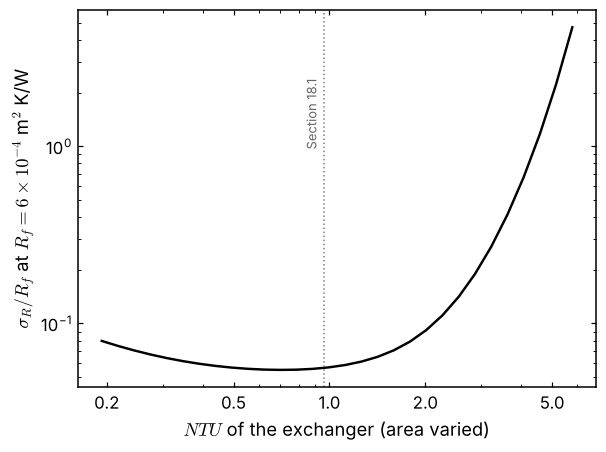

In [5]:
fig, ax = plt.subplots(figsize=(5.4, 4.0))
ax.loglog(ntu, sig_area / 0.6e-3, "k-")
ax.axvline(A / (1 / U_clean + 0.6e-3) / C_min0, color="0.5", ls=":", lw=1.0)
ax.text(0.93, 1.0, "Section 18.1", fontsize=8.5, color="0.4", rotation=90, ha="right")
ax.set_xticks([0.2, 0.5, 1, 2, 5])
ax.xaxis.set_major_formatter(plt.ScalarFormatter())
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel(r"$NTU$ of the exchanger (area varied)")
ax.set_ylabel(r"$\sigma_R/R_f$ at $R_f = 6\times10^{-4}$ m$^2$ K/W")
plt.show()

**Figure S18.1.** Relative uncertainty of a daily fouling resistance against the size of
the exchanger, for the instruments of Section 18.1.

The two flows and the two outlet temperatures contribute about equally, each near
$1.6\times10^{-5}$ m² K/W; the inlet temperatures matter little because they enter both
the duty and the driving difference. Better thermometers (0.1 K) cut the scatter by a
quarter, better flowmeters (0.5 %) by as much, and both together by 57 %: since both kinds
of error contribute, improving only one helps only so far. The size of the exchanger
matters more. A small exchanger (low NTU) changes its duty little when it fouls, so a
fouling resistance hides in the noise; a large one works close to its limiting
effectiveness, where a small error in $\varepsilon$ becomes a large error in NTU, and at
NTU 6 the daily scatter exceeds the resistance itself. Fouling is measured best near
NTU 0.7, and the exchanger of Section 18.1 (NTU 1.0) is close to that.

## Exercise 4. Cleaning in the cold season

With one cleaning a year on day $d$, the fouling restarts on day $d + t_d$ and the cost of a
year is the cleaning, the heat lost while out of service, and the heat lost to fouling, each
priced at the season's rate (twice the base rate from November to March: days 305 to 365
and 0 to 89).

In [6]:
price = lambda day: np.where((np.mod(day, 365) >= 305) | (np.mod(day, 365) < 90), 2.0, 1.0)
L_true = loss(law)
tt = np.arange(0.0, 365.0, 0.25)


def annual_cost(d):
    since = np.mod(tt - d - T_DOWN, 365.0)                    # days since the end of the cleaning
    down = np.mod(tt - d, 365.0) < T_DOWN
    rate = np.where(down, c_W * Q0, L_true(np.where(down, 0.0, since))) * price(tt)
    return C_CLEAN + float(np.sum(rate) * 0.25)


d_grid = np.arange(0.0, 365.0, 1.0)
yearly = np.array([annual_cost(d) for d in d_grid])
best = int(np.argmin(yearly))
print(f"best day to clean: day {d_grid[best]:.0f} of the year, {yearly[best] / 1e3:.1f} thousand USD;"
      f" worst day {d_grid[np.argmax(yearly)]:.0f}, {yearly.max() / 1e3:.1f} thousand USD")

best day to clean: day 303 of the year, 224.0 thousand USD; worst day 88, 263.7 thousand USD


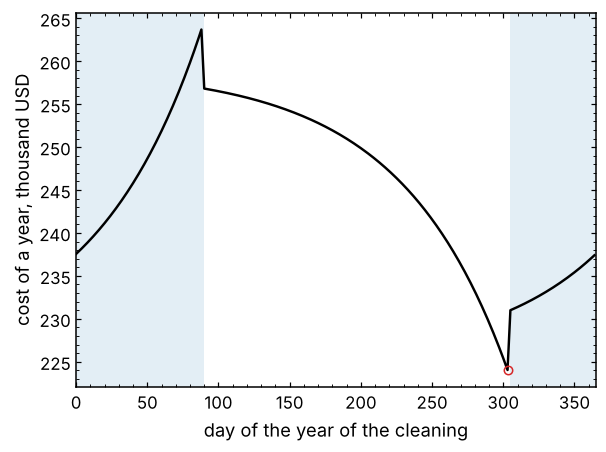

In [7]:
fig, ax = plt.subplots(figsize=(5.4, 4.0))
ax.plot(d_grid, yearly / 1e3, "k-")
ax.axvspan(305, 365, color="C0", alpha=0.12, lw=0)
ax.axvspan(0, 90, color="C0", alpha=0.12, lw=0)
ax.plot(d_grid[best], yearly[best] / 1e3, "C3o", mfc="none")
ax.set_xlabel("day of the year of the cleaning")
ax.set_ylabel("cost of a year, thousand USD")
ax.set_xlim(0, 365)
plt.show()

**Figure S18.2.** Cost of a year with one cleaning, against the day it is done, when lost
heat costs twice as much from November to March (shaded).

The best day is day 303, the end of October, just before the expensive season: the
exchanger enters the winter clean and its losses are smallest when heat is dearest.
Cleaning at the end of March (day 88), just as the cheap season starts, is the worst
choice: the exchanger then fouls through the summer and spends the whole winter fully
fouled. The difference is 40 thousand USD a year, 224 against 264 thousand, for the same
work.